# Emoji Classification Challenge — recognising the vendor style of an emoji

**Task.** Each image is an emoji rendered by one of 7 vendors (`apple`, `facebook`, `google`, `messenger`, `mozilla`, `samsung`, `whatsapp`). We must predict the vendor of the 9,879 unlabelled test images from 9,879 labelled training images, and submit a CSV with columns `Id,Label`.

**Pipeline at a glance**

| Step | Choice | Why |
|---|---|---|
| Decoding | every PNG mode (`RGBA`, `P`, `LA`, `L`, `RGB`) → RGBA → **premultiplied alpha** → pad to square → resize | transparent pixels hide vendor-specific colour values; premultiplying erases them and blends edges correctly |
| Background | composite on **white** at batch time | one consistent background for train and test |
| Model | **ConvNeXt-Tiny** pretrained on ImageNet-22k (`timm`), new 7-way head | strong transfer learning on a small dataset |
| Training | AdamW, one-cycle cosine LR, label smoothing, mixed precision | standard, stable fine-tuning recipe |
| Augmentation | **none**: rotation/zoom/shift clearly hurt, horizontal flip has no measurable effect (section 7); no colour jitter | vendor style lives in exact pixels: margins, scale, anti-aliasing, palette |
| Validation | **stratified group 5-fold** CV, groups = exact-duplicate fingerprint; out-of-fold (OOF) metrics | identical images never sit on both sides of a split, so the score is not inflated |
| Inference | average of the 5 fold models' probabilities, then **exact-duplicate lookup** for test images identical to a training image | ensembling reduces variance; duplicates have a known label |

**Reproducibility.** Run all cells top to bottom from the project folder (it must contain `train/`, `test/`, `train_labels.csv`). All random seeds are fixed and cuDNN runs in deterministic mode, so a rerun on the same hardware/software gives the same predictions. Package versions are printed below and listed in `requirements.txt`. Outputs go to `outputs/` and `submission.csv`.

## 0. Setup

In [1]:
import os
# Needed for deterministic cuBLAS matrix multiplications; must be set before CUDA is initialised.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import hashlib
import math
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import sklearn
import torch
import torch.nn.functional as F
import timm
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore", message="Palette images with Transparency")  # PIL notice in the section 2 demo

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | timm {timm.__version__} | "
      f"sklearn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__}")
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

python 3.12.10 | torch 2.11.0+cu128 | timm 1.0.30 | sklearn 1.9.1 | numpy 2.4.2 | pandas 3.0.1
CUDA available: True | NVIDIA GeForce RTX 4070 Laptop GPU


In [2]:
CFG = {
    "seed": 42,
    "n_folds": 5,
    "img_size": 160,                           # every image is resized to img_size x img_size
    "arch": "convnext_tiny.fb_in22k_ft_in1k",  # timm model name (ImageNet-22k pretrained, fine-tuned on 1k)
    "weights_revision": "bc48a87f119bae1b06418f5340bfa97ef75d4609",  # Hugging Face Hub commit of timm/<arch>: fixes the weights
    "epochs": 12,
    "batch_size": 64,
    "lr": 3e-4,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
    "warmup_pct": 0.1,                         # fraction of steps used for LR warm-up
    # augmentation (section 4): all off in the final recipe, see the ablation in section 7
    "hflip": False,                            # random horizontal flip during training
    "tta_hflip": False,                        # test-time augmentation: average with the mirrored image
    "geometric_aug": False,                    # random rotation / zoom / translation
    "aug_rotate_deg": 10,                      # only used when geometric_aug is True
    "aug_scale": (0.85, 1.15),
    "aug_translate": 0.08,                     # fraction of the image size
}

DATA_DIR = Path(os.environ.get("EMOJI_DATA_DIR", "."))
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
# bfloat16 on recent GPUs (RTX 30xx/40xx, A100...), float16 + gradient scaling otherwise (e.g. Kaggle T4)
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.is_bf16_supported() else torch.float16


def seed_everything(seed):
    """Fix every source of randomness we use (Python, NumPy, PyTorch CPU + GPU) and force deterministic cuDNN."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False      # always pick the same convolution algorithms...
    torch.backends.cudnn.deterministic = True   # ...and only deterministic ones
    # (torch.use_deterministic_algorithms(True) would also work but makes ConvNeXt training ~3x slower;
    #  with the settings above, two runs on the same machine already give bit-identical weights)


seed_everything(CFG["seed"])
print("device:", DEVICE, "| AMP dtype:", AMP_DTYPE if USE_AMP else None)

device: cuda | AMP dtype: torch.bfloat16


## 1. The data

9879 training images, 9879 test images, 7 classes: ['apple', 'facebook', 'google', 'messenger', 'mozilla', 'samsung', 'whatsapp']


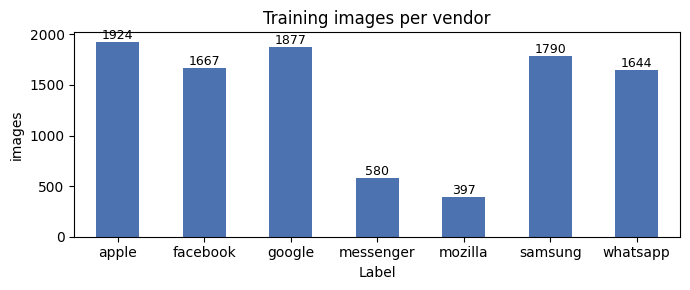

In [3]:
train_df = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"Id": str})   # keep leading zeros: "00001"
test_ids = sorted(p.stem for p in (DATA_DIR / "test").glob("*.png"))

CLASSES = sorted(train_df["Label"].unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
y = train_df["Label"].map(CLS2IDX).to_numpy(copy=True)   # integer class index per training image

assert all((DATA_DIR / "train" / f"{i}.png").exists() for i in train_df["Id"])
print(f"{len(train_df)} training images, {len(test_ids)} test images, {len(CLASSES)} classes: {CLASSES}")

counts = train_df["Label"].value_counts().reindex(CLASSES)
ax = counts.plot.bar(figsize=(7, 3), color="#4C72B0", title="Training images per vendor")
for i, v in enumerate(counts):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("images"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

The classes are **imbalanced**: `mozilla` (397) and `messenger` (580) are 4–5× rarer than `apple` (1,924). We therefore report **macro-F1** (every class weighs the same) next to accuracy, and use *stratified* folds so each fold keeps these proportions.

Unlike MNIST, the files are not uniform: they come in different sizes and PNG colour modes.

In [4]:
def image_meta(path):
    with Image.open(path) as im:
        return {"size": f"{im.width}x{im.height}", "mode": im.mode}

train_meta = pd.DataFrame([image_meta(DATA_DIR / "train" / f"{i}.png") for i in train_df["Id"]])
test_meta = pd.DataFrame([image_meta(DATA_DIR / "test" / f"{i}.png") for i in test_ids])

print("Native size per vendor (train):")
display(pd.crosstab(train_df["Label"], train_meta["size"]))
print("PNG colour mode per vendor (train):")
display(pd.crosstab(train_df["Label"], train_meta["mode"]))
print("Test set sizes:", test_meta["size"].value_counts().to_dict())
print("Test set modes:", test_meta["mode"].value_counts().to_dict())

Native size per vendor (train):


size,108x108,160x160,240x240,64x64,66x72,72x67,72x68,72x72
Label,,,,,,,,
apple,0,2,0,0,0,0,0,1922
facebook,0,0,1550,0,0,0,0,117
google,0,0,3,0,1,1,116,1756
messenger,0,0,572,0,0,0,0,8
mozilla,0,0,362,0,0,0,0,35
samsung,6,0,0,0,0,0,0,1784
whatsapp,0,1484,0,13,0,0,0,147


PNG colour mode per vendor (train):


mode,L,LA,P,RGB,RGBA
Label,,,,,
apple,0,17,101,0,1806
facebook,0,0,5,12,1650
google,1,35,1,1,1839
messenger,0,0,3,0,577
mozilla,0,0,19,0,378
samsung,0,0,1580,0,210
whatsapp,0,9,29,13,1593


Test set sizes: {'72x72': 5782, '240x240': 2454, '160x160': 1492, '72x68': 127, '64x64': 16, '108x108': 6, '72x63': 1, '240x221': 1}
Test set modes: {'RGBA': 8039, 'P': 1742, 'LA': 75, 'RGB': 23}


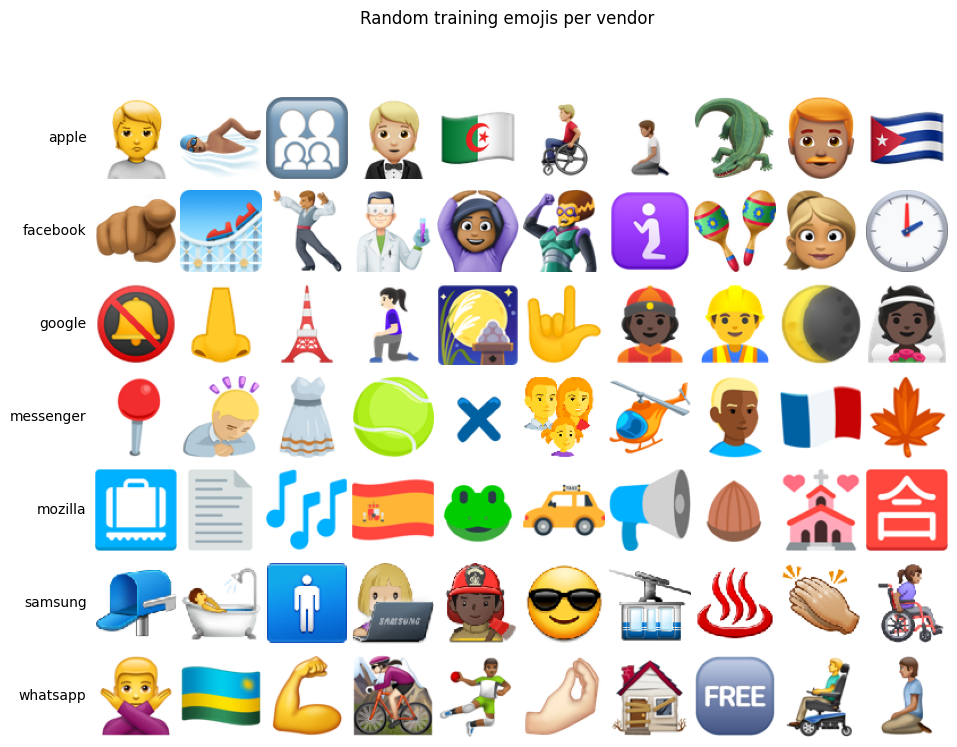

In [5]:
def show_grid(ids_per_row, folder, row_titles, n=10, cell=72, title=None):
    """Plot n images per row, each composited on white (see section 2)."""
    fig, axes = plt.subplots(len(ids_per_row), n, figsize=(n * 1.1, len(ids_per_row) * 1.2))
    axes = np.atleast_2d(axes)
    for r, ids in enumerate(ids_per_row):
        for c in range(n):
            ax = axes[r, c]; ax.axis("off")
            if c < len(ids):
                im = Image.open(DATA_DIR / folder / f"{ids[c]}.png").convert("RGBA")
                bg = Image.new("RGBA", im.size, (255, 255, 255, 255)); bg.alpha_composite(im)
                ax.imshow(bg.convert("RGB").resize((cell, cell)))
        axes[r, 0].text(-0.1, 0.5, row_titles[r], transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=10)
    if title: fig.suptitle(title)
    plt.subplots_adjust(wspace=0.05, hspace=0.05); plt.show()

rng = np.random.default_rng(0)
show_grid([rng.choice(train_df.loc[train_df.Label == c, "Id"].to_numpy(), 10, replace=False) for c in CLASSES],
          "train", CLASSES, title="Random training emojis per vendor")

## 2. Careful preprocessing: transparency

All files are PNGs with transparency (`RGBA`, palette `P` with a transparent index, grey-scale + alpha `LA`...). A fully transparent pixel is invisible, **but it still stores an RGB value**, and that hidden value depends on the tool each vendor used to export its images. A naive `Image.open(f).convert("RGB")` simply drops the alpha channel and exposes those hidden colours:

,mean R,mean G,mean B,std over images
apple,42.1,36.3,28.6,45.0
facebook,80.8,65.7,57.1,47.2
google,29.2,26.0,20.8,44.1
messenger,36.6,29.9,24.8,55.4
mozilla,8.9,8.9,8.5,35.8
samsung,71.6,97.7,100.3,24.0
whatsapp,64.9,52.2,42.4,41.6


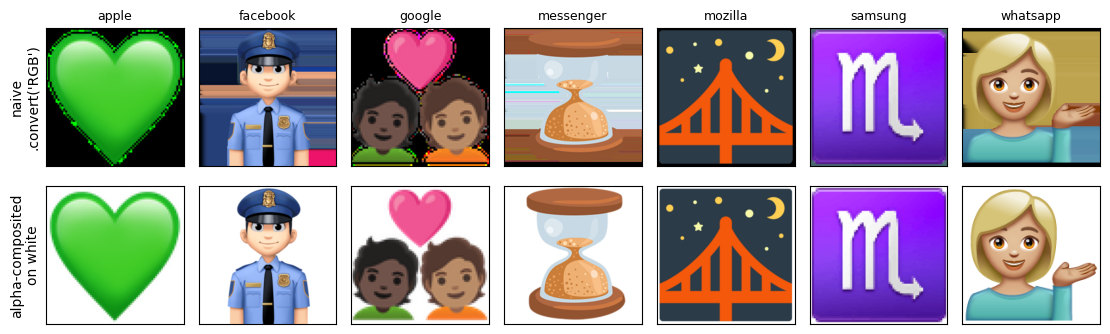

In [6]:
def hidden_rgb_stats(ids, n=200):
    """Mean RGB stored under fully transparent pixels (alpha == 0) for a sample of images."""
    vals = []
    for i in ids[:n]:
        a = np.asarray(Image.open(DATA_DIR / "train" / f"{i}.png").convert("RGBA"))
        mask = a[..., 3] == 0
        if mask.any():
            vals.append(a[mask][:, :3].mean(0))
    vals = np.array(vals)
    return pd.Series({"mean R": vals[:, 0].mean(), "mean G": vals[:, 1].mean(), "mean B": vals[:, 2].mean(),
                      "std over images": vals.std(0).mean()}).round(1)

print("Mean RGB stored under fully transparent pixels, per vendor "
      "(sample: the first 200 training images of each class, in file order):")
display(pd.DataFrame({c: hidden_rgb_stats(train_df.loc[train_df.Label == c, "Id"].to_numpy()) for c in CLASSES}).T)

fig, axes = plt.subplots(2, len(CLASSES), figsize=(len(CLASSES) * 1.6, 3.6))
for k, c in enumerate(CLASSES):
    i = train_df.loc[train_df.Label == c, "Id"].iloc[3]
    im = Image.open(DATA_DIR / "train" / f"{i}.png")
    axes[0, k].imshow(im.convert("RGB")); axes[0, k].set_title(c, fontsize=9)
    rgba = im.convert("RGBA"); bg = Image.new("RGBA", rgba.size, (255, 255, 255, 255)); bg.alpha_composite(rgba)
    axes[1, k].imshow(bg.convert("RGB"))
    for a in axes[:, k]: a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("naive\n.convert('RGB')"); axes[1, 0].set_ylabel("alpha-composited\non white")
plt.tight_layout(); plt.show()

The hidden colours are a potential **shortcut**: a network could learn "grey-blue background ⇒ samsung" instead of the drawing style, and such a rule would break as soon as the images are exported with another tool. (The ablation in section 7 shows that, on this dataset, the shortcut brings no measurable gain anyway, so removing it costs nothing.) We remove it with **premultiplied alpha**:

1. convert any mode to `RGBA` (palette and grey-scale images included);
2. multiply the RGB channels by alpha → hidden colours under `alpha = 0` become 0, semi-transparent edge pixels are weighted correctly;
3. pad non-square images (e.g. 72×68) with transparent pixels so they are not distorted;
4. resize to `img_size` with an anti-aliased bicubic filter. Resizing premultiplied colours avoids the dark/coloured halos you get when resizing straight RGBA;
5. at batch time, composite on a white background: `rgb = rgb_premultiplied + (1 − alpha) · white`.

We keep the 4-channel premultiplied tensors in memory as `uint8` (≈ 1 GB each for train and test at 160 px), so no disk cache and no `DataLoader` workers are needed (which also avoids multiprocessing issues in Jupyter on Windows).

In [7]:
def load_premultiplied(path, size, naive=False):
    """PNG (any mode) -> (uint8 tensor (4, size, size) of premultiplied RGB + alpha, fingerprint string).

    naive=True reproduces the common mistake Image.convert("RGB") (alpha dropped, hidden colours kept);
    it is only used in the ablation study of section 7.

    The fingerprint is an MD5 hash of the native-resolution premultiplied pixels: two files get the same
    fingerprint exactly when they look identical (hidden colours under transparent pixels are ignored).
    It is used for the duplicate-aware folds (end of section 2) and the duplicate lookup (section 6)."""
    img = Image.open(path)
    img = img.convert("RGB").convert("RGBA") if naive else img.convert("RGBA")
    img = np.asarray(img, dtype=np.float32) / 255.0
    x = torch.from_numpy(img).permute(2, 0, 1)                    # (4, H, W) in [0, 1]
    x = torch.cat([x[:3] * x[3:], x[3:]])                         # premultiply RGB by alpha
    fingerprint = hashlib.md5((x * 255).round().to(torch.uint8).numpy().tobytes() + str(tuple(x.shape)).encode()).hexdigest()
    h, w = x.shape[1:]
    if h != w:                                                    # pad to a square, centred, with transparent pixels
        s = max(h, w); top, left = (s - h) // 2, (s - w) // 2
        x = F.pad(x, (left, s - w - left, top, s - h - top), value=0.0)
    x = F.interpolate(x[None], size=(size, size), mode="bicubic", antialias=True, align_corners=False)[0]
    alpha = x[3:].clamp(0, 1)
    rgb = torch.minimum(x[:3].clamp_min(0), alpha)                # bicubic can overshoot: keep 0 <= rgb <= alpha
    return (torch.cat([rgb, alpha]) * 255).round().to(torch.uint8), fingerprint


def load_folder(ids, folder, size):
    out = [load_premultiplied(DATA_DIR / folder / f"{i}.png", size) for i in ids]
    return torch.stack([t for t, _ in out]), np.array([fp for _, fp in out])


t0 = time.time()
X_train, fp_train = load_folder(train_df["Id"], "train", CFG["img_size"])
X_test, fp_test = load_folder(test_ids, "test", CFG["img_size"])
print(f"X_train {tuple(X_train.shape)}  X_test {tuple(X_test.shape)}  ({time.time() - t0:.0f}s)")

X_train (9879, 4, 160, 160)  X_test (9879, 4, 160, 160)  (108s)


### Exact duplicates
The fingerprints reveal that some images appear several times. Looking at them, they are mostly people emojis (mainly in the facebook and whatsapp sets) whose default and explicitly gendered versions, e.g. *detective* and *man detective*, are drawn identically by the vendor. All copies of an image always carry the same label.

In [8]:
fp_groups = pd.Series(fp_train).groupby(fp_train)
dup_sizes = fp_groups.size()
labels_per_fp = train_df.groupby(fp_train)["Label"].nunique()
test_in_train = pd.Series(fp_test).isin(set(fp_train))

print(f"train: {len(dup_sizes)} distinct images, {(dup_sizes > 1).sum()} duplicate groups "
      f"covering {dup_sizes[dup_sizes > 1].sum()} images")
print(f"duplicate groups whose copies have DIFFERENT labels: {(labels_per_fp > 1).sum()}")
print(f"test images identical to at least one training image: {test_in_train.sum()} / {len(fp_test)}")

train: 9721 distinct images, 141 duplicate groups covering 299 images
duplicate groups whose copies have DIFFERENT labels: 0
test images identical to at least one training image: 352 / 9879


value of fully transparent pixels after compositing: min 1.0 max 1.0


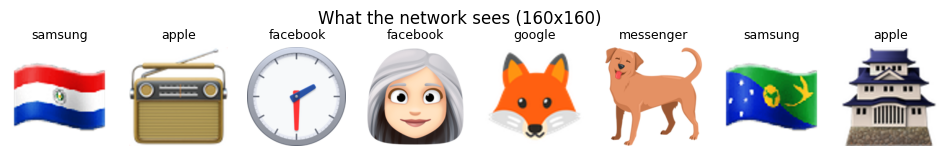

In [9]:
def composite_on_white(xb):
    """uint8 premultiplied RGBA batch (B,4,S,S) -> float RGB batch in [0,1] on DEVICE, over a white background."""
    x = xb.to(DEVICE, non_blocking=True).float() / 255.0
    rgb, alpha = x[:, :3], x[:, 3:]
    return rgb + (1.0 - alpha)

# sanity check: after preprocessing, transparent pixels are pure white for every vendor
check = composite_on_white(X_train[:512])
alpha0 = (X_train[:512, 3:] == 0).to(DEVICE).expand_as(check)
print("value of fully transparent pixels after compositing: min", check[alpha0].min().item(), "max", check[alpha0].max().item())

fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, k in zip(axes, range(8)):
    ax.imshow(composite_on_white(X_train[k:k + 1])[0].permute(1, 2, 0).cpu()); ax.set_title(train_df.Label[k], fontsize=9); ax.axis("off")
plt.suptitle(f"What the network sees ({CFG['img_size']}x{CFG['img_size']})"); plt.show()

### Cross-validation folds that respect duplicates
If two copies of the same image ended up in different folds, the model would be validated on an image it has already seen during training, and the validation score would be optimistic. We therefore use **`StratifiedGroupKFold`** with the fingerprint as group: all copies of an image always fall in the same fold, while each fold keeps the class proportions.

In [10]:
sgkf = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
FOLDS = list(sgkf.split(np.zeros(len(y)), y, groups=fp_train))

for k, (tr_idx, va_idx) in enumerate(FOLDS):
    assert not set(fp_train[tr_idx]) & set(fp_train[va_idx])      # no image shared between train and validation
    print(f"fold {k}: {len(tr_idx)} train / {len(va_idx)} validation | validation class shares:",
          np.round(np.bincount(y[va_idx], minlength=len(CLASSES)) / len(va_idx), 3))

fold 0: 7903 train / 1976 validation | validation class shares: [0.195 0.169 0.19  0.059 0.04  0.181 0.166]
fold 1: 7903 train / 1976 validation | validation class shares: [0.195 0.169 0.19  0.059 0.04  0.181 0.166]
fold 2: 7903 train / 1976 validation | validation class shares: [0.195 0.169 0.19  0.059 0.04  0.181 0.166]
fold 3: 7903 train / 1976 validation | validation class shares: [0.195 0.169 0.19  0.059 0.04  0.181 0.166]
fold 4: 7904 train / 1975 validation | validation class shares: [0.194 0.169 0.19  0.059 0.04  0.181 0.167]


### Near duplicates across folds (check only)
The groups above only catch *exact* copies. The same drawing can also come back slightly changed: re-exported at another size, re-compressed, or with a few pixels edited. We look for such near duplicates with a 64-bit **perceptual hash** (pHash, `imagehash`) of every training image as it is seen (composited on white, at native size); two images whose hashes differ in only a few bits look almost the same. For each Hamming-distance threshold we count the pairs that are *not* exact duplicates and how many of them sit on both sides of a fold split. A same-label pair across a split is a potential leak (the model may have seen a near copy of a validation image); a different-label pair is two vendors drawing an emoji almost the same way, which is a genuinely hard case, not a leak.

Caveat: pHash works on a small greyscale version of the image, so colour variants of one drawing (skin tones, hair colour, flags with the same layout) get the same hash. Many of the pairs counted below are such variants rather than re-exported copies; they share the vendor's line work, which makes them a milder form of overlap. This is a check only: the folds above are not changed.

In [ ]:
def phash_on_white(path):
    """64-bit perceptual hash of the image as it is seen: composited on white, at its native size."""
    with Image.open(path) as im:
        rgba = im.convert("RGBA")
    bg = Image.new("RGBA", rgba.size, (255, 255, 255, 255)); bg.alpha_composite(rgba)
    return int(str(imagehash.phash(bg.convert("RGB"))), 16)


phash_train = np.array([phash_on_white(DATA_DIR / "train" / f"{i}.png") for i in train_df["Id"]], dtype=np.uint64)
fold_of = np.empty(len(y), dtype=int)
for k, (_, va_idx) in enumerate(FOLDS):
    fold_of[va_idx] = k

# all pairs i < j within Hamming distance MAX_DIST, computed in row blocks to bound memory
MAX_DIST = 8
pi, pj, pd_ = [], [], []
for start in range(0, len(phash_train), 1024):
    dist = np.bitwise_count(phash_train[start:start + 1024, None] ^ phash_train[None, :])
    i, j = np.nonzero(dist <= MAX_DIST)
    keep = j > i + start
    pi.append(i[keep] + start); pj.append(j[keep]); pd_.append(dist[i[keep], j[keep]])
pi, pj, pd_ = np.concatenate(pi), np.concatenate(pj), np.concatenate(pd_)

near = fp_train[pi] != fp_train[pj]                   # exact duplicates are already grouped in one fold
cross = near & (fold_of[pi] != fold_of[pj])
same_label = y[pi] == y[pj]
display(pd.DataFrame([{"max Hamming distance": t,
                       "near-duplicate pairs": (near & (pd_ <= t)).sum(),
                       "across folds": (cross & (pd_ <= t)).sum(),
                       "across folds, same label": (cross & same_label & (pd_ <= t)).sum(),
                       "across folds, different label": (cross & ~same_label & (pd_ <= t)).sum()}
                      for t in (0, 2, 4, 6, 8)]).set_index("max Hamming distance"))


## 3. A metadata-only baseline (and why we do not use it)

The native size and colour mode are strongly tied to the vendor (e.g. only whatsapp is 160×160). How far does that go *without looking at a single pixel*?

In [11]:
meta_X = pd.get_dummies(train_meta[["size", "mode"]]).to_numpy()
meta_pred = cross_val_predict(DecisionTreeClassifier(random_state=CFG["seed"]), meta_X, y, cv=FOLDS)
print(f"metadata-only decision tree: accuracy {accuracy_score(y, meta_pred):.4f} | "
      f"macro-F1 {f1_score(y, meta_pred, average='macro'):.4f}")

metadata-only decision tree: accuracy 0.6670 | macro-F1 0.4863


About two thirds of the images can be classified from file metadata alone, but it cannot separate the many 72×72 `RGBA` images (apple, google, samsung, ...) nor facebook / messenger / mozilla at 240×240. It is a shortcut, not the visual style we are asked to recognise, so the CNN below only receives pixels: everything is resized to the same square size and composited on the same background. (The original resolution is still indirectly visible — a 72 px image upscaled to 160 px is blurrier — which is unavoidable.)

## 4. Model and training

* **Backbone — ConvNeXt-Tiny** (28 M parameters) pretrained on ImageNet-22k: a modern CNN whose pretrained features transfer very well to small datasets. `timm` replaces the 1000-class head by a 7-class one. The weights are downloaded from a fixed Hugging Face Hub commit (`CFG["weights_revision"]`), so they cannot change between runs.
* **Optimiser** — AdamW (lr 3e-4, weight decay 0.05) with PyTorch's `OneCycleLR` schedule: the learning rate rises from lr/25 to lr during the first 10 % of the steps (warm-up, so the new random head does not wreck the pretrained weights), then follows a cosine decay to almost 0. `OneCycleLR` also moves Adam's β1 between 0.95 and 0.85 in the opposite direction.
* **Loss** — cross-entropy with label smoothing 0.1 (prevents over-confident predictions).
* **Mixed precision** (bfloat16) roughly halves memory and time on the GPU.
* **No data augmentation.** This is unusual for a small image dataset, and it is a measured choice (ablation in section 7):
  * random rotation / zoom / translation clearly *hurts*. Our interpretation: each vendor draws its emojis on a fixed canvas with consistent margins, size and position, and renders them with crisp, vendor-specific anti-aliasing; resampling the image to rotate or zoom it shifts and blurs exactly those cues;
  * a random horizontal flip (an exact mirror, no resampling) together with flip test-time augmentation makes no measurable difference, so we keep the simpler pipeline;
  * colour jitter is excluded by design, since the colour palette is a key part of a vendor's style.

  The augmentation code is kept (`geometric_aug`, `hflip`, `tta_hflip`) so that the ablation can be reproduced.

All helpers below take a configuration dictionary, so the same code trains the final model and the ablation variants.

In [12]:
def normalize(img, model):
    """Standardise with the mean/std the backbone was pretrained with."""
    mean = torch.tensor(model.pretrained_cfg["mean"], device=img.device).view(1, 3, 1, 1)
    std = torch.tensor(model.pretrained_cfg["std"], device=img.device).view(1, 3, 1, 1)
    return ((img - mean) / std).contiguous(memory_format=torch.channels_last)


def augment(img, cfg):
    """Training-time augmentation on a GPU batch of RGB images in [0, 1]."""
    B = img.size(0)
    if cfg["geometric_aug"]:   # random rotation / zoom / translation, one affine transform per image
        u = lambda lo, hi: torch.empty(B, device=img.device).uniform_(lo, hi)
        angle = u(-1, 1) * math.radians(cfg["aug_rotate_deg"])
        scale = u(*cfg["aug_scale"])
        tx, ty = u(-1, 1) * cfg["aug_translate"], u(-1, 1) * cfg["aug_translate"]
        cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
        theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)  # (B, 2, 3)
        grid = F.affine_grid(theta, list(img.shape), align_corners=False)
        # grid_sample pads with zeros: sampling (1 - img) and flipping back pads with white instead
        img = 1 - F.grid_sample(1 - img, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    if cfg["hflip"]:           # exact mirror of a random half of the batch (no resampling)
        flip = torch.rand(B, device=img.device) < 0.5
        img = torch.where(flip.view(B, 1, 1, 1), img.flip(3), img)
    return img


@torch.no_grad()
def predict_proba(model, X, cfg, batch_size=256):
    """Softmax probabilities; averaged with the mirrored image if test-time augmentation is on."""
    model.eval()
    out = []
    for k in range(0, len(X), batch_size):
        img = composite_on_white(X[k:k + batch_size])
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            p = model(normalize(img, model)).float().softmax(1)
            if cfg["tta_hflip"]:
                p = (p + model(normalize(img.flip(3), model)).float().softmax(1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()


def train_one_fold(cfg, X, tr_idx, va_idx, seed, tag=""):
    """Fine-tune a fresh pretrained model on X[tr_idx]; return it with its validation probabilities and history."""
    seed_everything(seed)                       # every run is reproducible on its own
    hf_hub_id = f"timm/{cfg['arch']}@{cfg['weights_revision']}"   # timm reads the revision after '@'
    model = timm.create_model(cfg["arch"], pretrained=True, num_classes=len(CLASSES),
                              pretrained_cfg_overlay=dict(hf_hub_id=hf_hub_id))
    model = model.to(DEVICE).to(memory_format=torch.channels_last)
    bs = cfg["batch_size"]
    steps_per_epoch = len(tr_idx) // bs         # the last incomplete batch of each epoch is dropped
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch,
                                                pct_start=cfg["warmup_pct"], anneal_strategy="cos")
    scaler = torch.amp.GradScaler(enabled=USE_AMP and AMP_DTYPE == torch.float16)
    y_t = torch.as_tensor(y)
    history = []
    for epoch in range(cfg["epochs"]):
        model.train()
        t0, run_loss = time.time(), 0.0
        perm = np.random.permutation(tr_idx)
        for k in range(steps_per_epoch):
            idx = perm[k * bs:(k + 1) * bs]
            img = augment(composite_on_white(X[idx]), cfg)
            target = y_t[idx].to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = F.cross_entropy(model(normalize(img, model)), target, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += loss.item()
        va_proba = predict_proba(model, X[va_idx], cfg)
        va_pred = va_proba.argmax(1)
        rec = {"run": tag, "epoch": epoch + 1, "train_loss": run_loss / steps_per_epoch,
               "val_loss": F.nll_loss(torch.log(torch.as_tensor(va_proba).clamp_min(1e-8)), y_t[va_idx]).item(),
               "val_acc": accuracy_score(y[va_idx], va_pred),
               "val_macro_f1": f1_score(y[va_idx], va_pred, average="macro"), "sec": time.time() - t0}
        history.append(rec)
        print(f"{tag} | epoch {epoch + 1:2d}/{cfg['epochs']} | train loss {rec['train_loss']:.4f} | "
              f"val loss {rec['val_loss']:.4f} | val acc {rec['val_acc']:.4f} | "
              f"val macro-F1 {rec['val_macro_f1']:.4f} | {rec['sec']:.0f}s")
    return model, va_proba, history

### 5-fold cross-validation training
For each fold the model is trained on 4/5 of the data and evaluated on the remaining 1/5; its predictions on those held-out images are the *out-of-fold* (OOF) predictions, and it also predicts the test set. The final test prediction is the average of the 5 fold models' probabilities.

In [13]:
oof_proba = np.zeros((len(y), len(CLASSES)), dtype=np.float32)
test_proba = np.zeros((len(test_ids), len(CLASSES)), dtype=np.float32)
history = []

t_start = time.time()
for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    model, va_proba, hist = train_one_fold(CFG, X_train, tr_idx, va_idx, seed=CFG["seed"] + fold, tag=f"fold {fold}")
    oof_proba[va_idx] = va_proba
    test_proba += predict_proba(model, X_test, CFG) / len(FOLDS)
    history += [dict(h, fold=fold) for h in hist]
    print(f"==> fold {fold}: acc {hist[-1]['val_acc']:.4f}, macro-F1 {hist[-1]['val_macro_f1']:.4f}\n")
    del model
    torch.cuda.empty_cache()

print(f"total training time: {(time.time() - t_start) / 60:.1f} min")
history = pd.DataFrame(history)
history.to_csv(OUT_DIR / "history.csv", index=False)
np.save(OUT_DIR / "oof_proba.npy", oof_proba)
np.save(OUT_DIR / "test_proba.npy", test_proba)

fold 0 | epoch  1/12 | train loss 1.0480 | val loss 0.2891 | val acc 0.9226 | val macro-F1 0.9044 | 47s


fold 0 | epoch  2/12 | train loss 0.5525 | val loss 0.2027 | val acc 0.9641 | val macro-F1 0.9628 | 17s


fold 0 | epoch  3/12 | train loss 0.4804 | val loss 0.2384 | val acc 0.9484 | val macro-F1 0.9537 | 16s


fold 0 | epoch  4/12 | train loss 0.4666 | val loss 0.2120 | val acc 0.9570 | val macro-F1 0.9617 | 16s


fold 0 | epoch  5/12 | train loss 0.4602 | val loss 0.1754 | val acc 0.9706 | val macro-F1 0.9657 | 16s


...

fold 4 | epoch  9/12 | train loss 0.4466 | val loss 0.1468 | val acc 0.9808 | val macro-F1 0.9809 | 18s


fold 4 | epoch 10/12 | train loss 0.4466 | val loss 0.1469 | val acc 0.9803 | val macro-F1 0.9805 | 19s


fold 4 | epoch 11/12 | train loss 0.4465 | val loss 0.1468 | val acc 0.9803 | val macro-F1 0.9805 | 18s


fold 4 | epoch 12/12 | train loss 0.4465 | val loss 0.1468 | val acc 0.9803 | val macro-F1 0.9805 | 18s


==> fold 4: acc 0.9803, macro-F1 0.9805

total training time: 17.4 min


## 5. Evaluation (out-of-fold)
Every training image is predicted by the one model that did not see it during training, so these numbers estimate the score on unseen data.

In [14]:
oof_pred = oof_proba.argmax(1)
fold_scores = history.groupby("fold").last()[["val_acc", "val_macro_f1"]]
display(fold_scores.round(4))
print(f"OOF accuracy : {accuracy_score(y, oof_pred):.4f}  (std over folds {fold_scores.val_acc.std():.4f})")
print(f"OOF macro-F1 : {f1_score(y, oof_pred, average='macro'):.4f}")
print(f"metadata-only baseline: accuracy {accuracy_score(y, meta_pred):.4f}, "
      f"macro-F1 {f1_score(y, meta_pred, average='macro'):.4f}\n")
print(classification_report(y, oof_pred, target_names=CLASSES, digits=4))

,val_acc,val_macro_f1
fold,,
0,0.9787,0.9799
1,0.9661,0.9678
2,0.9747,0.9740
3,0.9782,0.9789
4,0.9803,0.9805


OOF accuracy : 0.9756  (std over folds 0.0057)
OOF macro-F1 : 0.9762
metadata-only baseline: accuracy 0.6670, macro-F1 0.4863

              precision    recall  f1-score   support

       apple     0.9400    0.9766    0.9579      1924
    facebook     0.9884    0.9682    0.9782      1667
      google     0.9732    0.9867    0.9799      1877
   messenger     0.9777    0.9828    0.9802       580
     mozilla     0.9796    0.9698    0.9747       397
     samsung     0.9887    0.9804    0.9846      1790
    whatsapp     0.9937    0.9629    0.9781      1644

    accuracy                         0.9756      9879
   macro avg     0.9773    0.9753    0.9762      9879
weighted avg     0.9760    0.9756    0.9757      9879



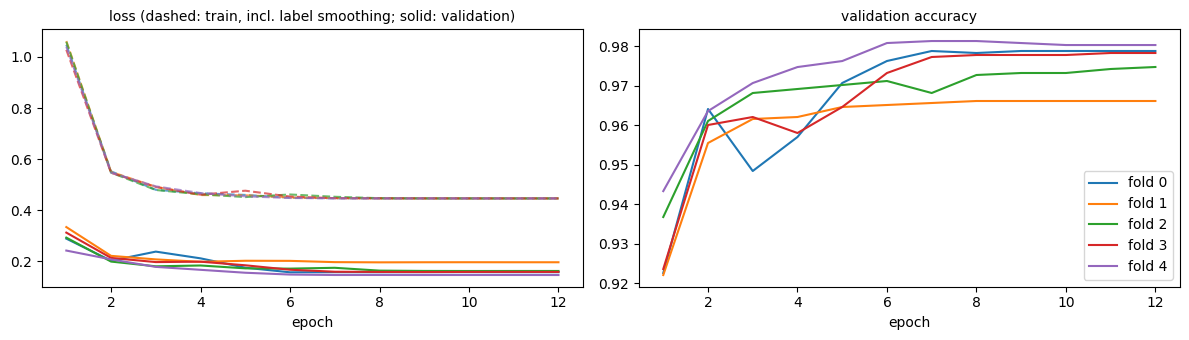

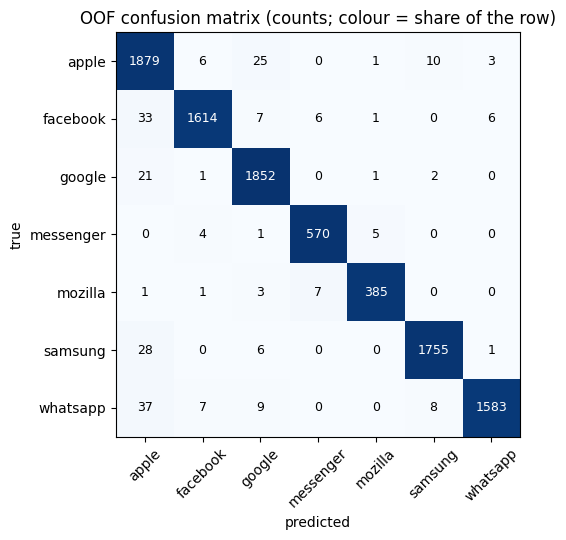

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for fold, h in history.groupby("fold"):
    axes[0].plot(h.epoch, h.train_loss, color=f"C{fold}", ls="--", alpha=0.7)
    axes[0].plot(h.epoch, h.val_loss, color=f"C{fold}", label=f"fold {fold}")
    axes[1].plot(h.epoch, h.val_acc, color=f"C{fold}", label=f"fold {fold}")
axes[0].set_title("loss (dashed: train, incl. label smoothing; solid: validation)", fontsize=10)
axes[0].set_xlabel("epoch")
axes[1].set_title("validation accuracy", fontsize=10); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

cm = confusion_matrix(y, oof_pred)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if i == j else "black", fontsize=9)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("OOF confusion matrix (counts; colour = share of the row)")
plt.tight_layout(); plt.show()

241 misclassified training images out of 9879


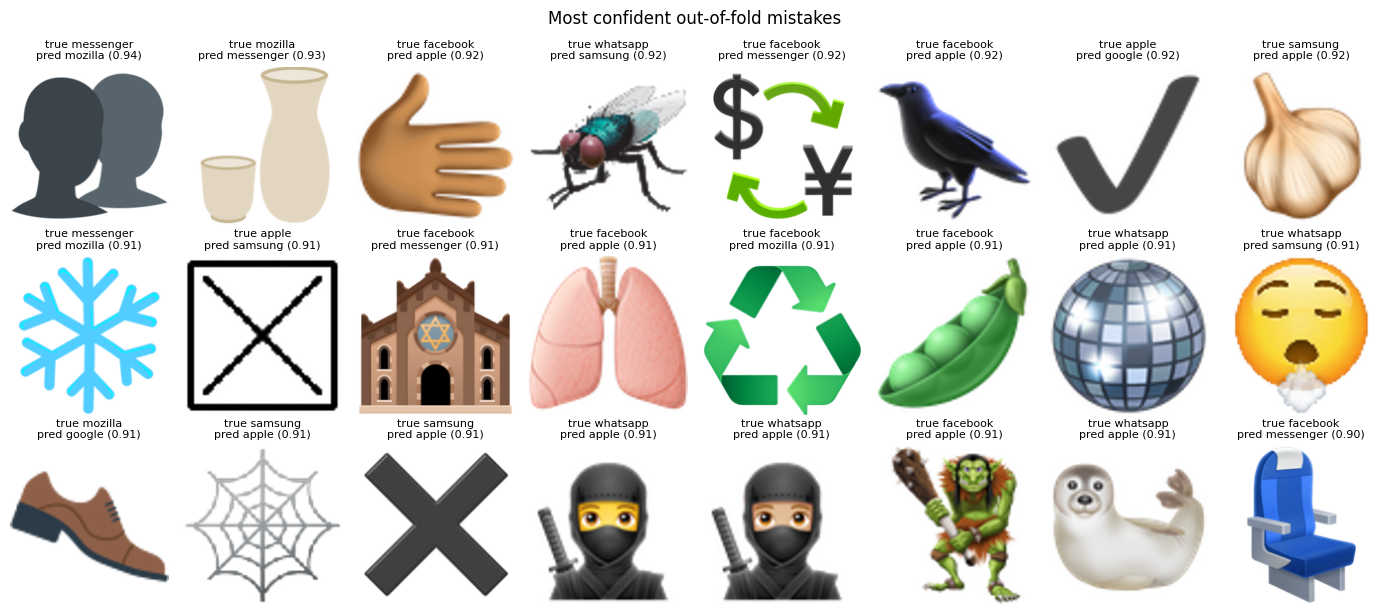

In [16]:
wrong = np.where(oof_pred != y)[0]
print(f"{len(wrong)} misclassified training images out of {len(y)}")
show = wrong[np.argsort(-oof_proba[wrong].max(1))][:24]          # most confident mistakes first
fig, axes = plt.subplots(3, 8, figsize=(14, 6.3))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, show):
    ax.imshow(composite_on_white(X_train[i:i + 1])[0].permute(1, 2, 0).cpu())
    ax.set_title(f"true {CLASSES[y[i]]}\npred {CLASSES[oof_pred[i]]} ({oof_proba[i].max():.2f})", fontsize=8)
plt.suptitle("Most confident out-of-fold mistakes"); plt.tight_layout(); plt.show()

### Where do the errors come from?
Most vendors deliver almost all their emojis at one "usual" size (e.g. whatsapp 160×160, facebook 240×240), but a few hundred images come at another, usually smaller, size. We compare the out-of-fold accuracy on both groups.

In [17]:
usual_size = train_meta.groupby(train_df["Label"])["size"].agg(lambda s: s.mode()[0])   # most common size per vendor
is_usual = (train_meta["size"] == train_df["Label"].map(usual_size)).to_numpy()
correct = oof_pred == y

display(pd.DataFrame({
    "images": [is_usual.sum(), (~is_usual).sum()],
    "OOF accuracy": [correct[is_usual].mean(), correct[~is_usual].mean()],
    "errors": [(~correct[is_usual]).sum(), (~correct[~is_usual]).sum()],
}, index=["vendor's usual size", "other size"]).round(4))

display(pd.DataFrame({"vendor": train_df["Label"], "native size": train_meta["size"], "correct": correct})
        .groupby(["vendor", "native size"])["correct"].agg(images="size", accuracy="mean")
        .query("images >= 5").round(3))

,images,OOF accuracy,errors
vendor's usual size,9430,0.9859,133
other size,449,0.7595,108


images  accuracy
vendor    native size                  
apple     72x72          1922     0.978
facebook  240x240        1550     0.992
          72x72           117     0.650
google    72x68           116     1.000
          72x72          1756     0.986
messenger 240x240         572     0.983
          72x72             8     1.000
mozilla   240x240         362     0.978
          72x72            35     0.886
samsung   108x108           6     0.500
          72x72          1784     0.982
whatsapp  160x160        1484     0.997
          64x64            13     0.538
          72x72           147     0.653

The model is very accurate on images at their vendor's usual size, but much weaker on the small "off-size" images: e.g. facebook or whatsapp emojis delivered at 72×72 instead of 240×240 / 160×160. They make up less than 5 % of the data but almost half of the errors. At 72 px much of the fine detail that separates vendors is gone, and 72×72 is precisely the usual size of apple, google and samsung, so most of these mistakes are predicted as one of those three (mostly apple, see the confusion matrix). With only a few dozen to ~150 training examples per vendor at those sizes, this is the hardest part of the problem. (The exception is google's 72×68 images: almost the same size as its usual 72×72, and classified as well as the rest.)

## 6. Test predictions and submission

1. **Model prediction**: average of the 5 fold models' probabilities, arg-max over classes.
2. **Duplicate lookup**: when a test image is pixel-identical to a training image (section 2), we copy the training label. This is a 1-nearest-neighbour rule at distance 0; it is safe here because no two identical training images carry different labels. We report how many predictions it changes.

In [18]:
model_labels = np.array(CLASSES)[test_proba.argmax(1)]

label_of_fp = train_df.groupby(fp_train)["Label"].first()        # well defined: duplicates never disagree (section 2)
assert (labels_per_fp == 1).all()
lookup = pd.Series(fp_test).map(label_of_fp).to_numpy()          # training label, or NaN if no identical image
matched = pd.notna(lookup)
final_labels = np.where(matched, lookup, model_labels)
print(f"duplicate lookup: {matched.sum()} test images matched; the model already agreed on "
      f"{(model_labels[matched] == lookup[matched]).sum()} of them, "
      f"{(final_labels != model_labels).sum()} predictions changed")

submission = pd.DataFrame({"Id": test_ids, "Label": final_labels})

# sanity checks on the file format
assert len(submission) == len(test_ids) == submission["Id"].nunique()
assert set(submission["Label"]) <= set(CLASSES)

submission.to_csv("submission.csv", index=False)

# read the written file back and check it against the test folder: every test image exactly once, Ids as strings
written = pd.read_csv("submission.csv", dtype={"Id": str})
test_files = sorted(p.stem for p in (DATA_DIR / "test").glob("*.png"))
assert list(written.columns) == ["Id", "Label"]
assert written["Id"].tolist() == test_files, "submission Ids do not match the test file names"
assert written["Label"].isin(CLASSES).all()
print("saved submission.csv", submission.shape)
display(submission.head())
display(pd.DataFrame({"train share": train_df["Label"].value_counts(normalize=True),
                      "test predicted share": submission["Label"].value_counts(normalize=True)}).round(3))

duplicate lookup: 352 test images matched; the model already agreed on 352 of them, 0 predictions changed
saved submission.csv (9879, 2)


,Id,Label
0,10001,google
1,10002,messenger
2,10003,samsung
3,10004,whatsapp
4,10005,samsung


,train share,test predicted share
Label,,
apple,0.195,0.196
facebook,0.169,0.159
google,0.190,0.196
messenger,0.059,0.061
mozilla,0.040,0.042
samsung,0.181,0.183
whatsapp,0.166,0.163


## 7. Ablation study: why these choices?

Each variant below changes **one** thing in the final recipe and is trained on fold 0 with exactly the same seed, epochs and optimiser; the final recipe's own fold-0 score comes from section 4. Set `RUN_ABLATION = False` to skip this section (it adds about 3 training runs).

| variant | what changes |
|---|---|
| `+ geometric augmentation` | random rotation ±10°, zoom 0.85–1.15, translation ±8 % (bilinear resampling) |
| `+ horizontal flip (train + TTA)` | random horizontal flip during training, and predictions averaged with the mirrored image |
| `naive RGB conversion` | `Image.convert("RGB")` instead of premultiplied alpha + white background: hidden colours under transparent pixels are visible to the network |

In [19]:
RUN_ABLATION = True

if RUN_ABLATION:
    tr_idx, va_idx = FOLDS[0]
    variants = {
        "+ geometric augmentation": (dict(CFG, geometric_aug=True), X_train),
        "+ horizontal flip (train + TTA)": (dict(CFG, hflip=True, tta_hflip=True), X_train),
    }
    ablation = [{"variant": "final recipe", **history.query("fold == 0").iloc[-1][["val_acc", "val_macro_f1"]].to_dict()}]
    for name, (cfg, X) in variants.items():
        _, va_proba, hist = train_one_fold(cfg, X, tr_idx, va_idx, seed=CFG["seed"], tag=name)
        ablation.append({"variant": name, "val_acc": hist[-1]["val_acc"], "val_macro_f1": hist[-1]["val_macro_f1"]})
        torch.cuda.empty_cache()

    # naive preprocessing: alpha dropped as-is (hidden colours exposed); same padding/resizing/training otherwise
    X_naive = torch.stack([load_premultiplied(DATA_DIR / "train" / f"{i}.png", CFG["img_size"], naive=True)[0]
                           for i in train_df["Id"]])
    _, va_proba, hist = train_one_fold(CFG, X_naive, tr_idx, va_idx, seed=CFG["seed"], tag="naive RGB conversion")
    ablation.append({"variant": "naive RGB conversion", "val_acc": hist[-1]["val_acc"], "val_macro_f1": hist[-1]["val_macro_f1"]})
    del X_naive
    torch.cuda.empty_cache()

    ablation = pd.DataFrame(ablation).set_index("variant").round(4)
    ablation.to_csv(OUT_DIR / "ablation.csv")
    display(ablation)

+ geometric augmentation | epoch  1/12 | train loss 1.1203 | val loss 0.3597 | val acc 0.8912 | val macro-F1 0.8842 | 20s


+ geometric augmentation | epoch  2/12 | train loss 0.6002 | val loss 0.3328 | val acc 0.9124 | val macro-F1 0.8991 | 20s


+ geometric augmentation | epoch  3/12 | train loss 0.5143 | val loss 0.2212 | val acc 0.9504 | val macro-F1 0.9522 | 17s


+ geometric augmentation | epoch  4/12 | train loss 0.4833 | val loss 0.2403 | val acc 0.9423 | val macro-F1 0.9446 | 17s


+ geometric augmentation | epoch  5/12 | train loss 0.4683 | val loss 0.2377 | val acc 0.9474 | val macro-F1 0.9526 | 17s


...

naive RGB conversion | epoch  9/12 | train loss 0.4466 | val loss 0.1572 | val acc 0.9787 | val macro-F1 0.9780 | 16s


naive RGB conversion | epoch 10/12 | train loss 0.4466 | val loss 0.1564 | val acc 0.9782 | val macro-F1 0.9776 | 15s


naive RGB conversion | epoch 11/12 | train loss 0.4465 | val loss 0.1565 | val acc 0.9782 | val macro-F1 0.9776 | 15s


naive RGB conversion | epoch 12/12 | train loss 0.4465 | val loss 0.1566 | val acc 0.9782 | val macro-F1 0.9776 | 15s


,val_acc,val_macro_f1
variant,,
final recipe,0.9787,0.9799
+ geometric augmentation,0.9514,0.9537
+ horizontal flip (train + TTA),0.9747,0.9754
naive RGB conversion,0.9782,0.9776


**Reading the ablation.** A fold has 1,976 validation images, so one image is worth 0.05 accuracy points, and differences of a few tenths of a point (5–8 images) are within the noise between splits and seeds.

* **Geometric augmentation: −2.7 points** of accuracy (macro-F1 0.954 vs 0.980). A clear loss, and it was also the largest effect in our preliminary experiments.
* **Horizontal flip (+ flip TTA): −0.4 points** here, but +0.4 points in a preliminary experiment on a different split, so no measurable effect. Over the full 5-fold cross-validation the two recipes are equivalent: setting `hflip` and `tta_hflip` to `True` in `CFG` gives an OOF accuracy of 97.52 % (macro-F1 0.9746) vs 97.56 % (0.9762) without. We keep the simpler pipeline.
* **Naive RGB conversion: −0.05 points**, i.e. the same score. The network does not need the hidden colours to reach this accuracy, so the clean preprocessing costs nothing while guaranteeing that the model only uses what is actually visible.

## 8. Summary

| model | OOF accuracy | OOF macro-F1 |
|---|---|---|
| metadata only (decision tree on native size + PNG mode) | 66.70 % | 0.486 |
| **ConvNeXt-Tiny, 5-fold ensemble (final)** | **97.56 %** | **0.976** |

Accuracy per fold ranges from 96.6 % to 98.0 % (std 0.6 point). The test predictions are the average of the 5 fold models.

**What mattered**

1. **Careful decoding of the PNGs.** All modes (`RGBA`, `P`, `LA`, `L`, `RGB`) are converted to premultiplied RGBA, padded to a square, resized, and composited on white. This removes the hidden colours stored under transparent pixels and gives the network clean, comparable inputs.
2. **Honest validation.** Exact duplicates (141 groups in train) are kept in the same fold with `StratifiedGroupKFold`. The 352 test images identical to a training image get the training label (the model already predicted all of them correctly).
3. **Transfer learning without augmentation.** A pretrained ConvNeXt-Tiny fine-tuned for 12 epochs is enough. The usual geometric augmentations *hurt* (−2.7 points), because a vendor's style lives in exact pixels.
4. **The remaining errors are mostly the "off-size" images.** Images at their vendor's usual size are classified at 98.6 %, the 449 others at 76.0 %: 4.5 % of the data, 45 % of the errors, most of them predicted as apple, google or samsung, which share the 72×72 format.

**Reproducibility.** Seeds are fixed and cuDNN is deterministic. Two complete, independent runs of this notebook gave identical losses and accuracies at every epoch. Runtime on an RTX 4070 Laptop GPU: about 2 min of image loading, 18 min of 5-fold training and 11 min of ablation.

**Exploratory runs (not in this notebook).** While designing the pipeline we also tried 224 px inputs, 15 epochs, ConvNeXt-Small and EfficientNetV2-S on a single fold. None beat ConvNeXt-Tiny at 160 px by more than the noise level, at 1.5–2× the training cost.

**Ideas to go further.** Treat the small images specifically, e.g. by feeding the network the image at its native resolution as well, or by over-sampling the off-size images. Other options are ensembling different backbones and pseudo-labelling the confident test predictions.